# 11 · Player Workload Index

**What this is:** a summary of how much a player has been asked to play
recently, from the minutes the data records.

**What this is not:** a measure of fatigue or injury risk. That would need
training load, GPS/tracking data and medical information, none of which
the open data contains. The index is called *workload*, never *fatigue*.

The index (`barca.analytics.workload`) is computed for every candidate
player before every Barcelona fixture (`player_fixture` table), using only
earlier matches. It combines five components, each capped at 1:

| Component | Weight | Reaches 1.0 at |
|---|---|---|
| minutes, last 7 days | 0.30 | 180 (two full matches) |
| minutes, last 14 days | 0.25 | 360 (four full matches) |
| minutes, last 30 days | 0.15 | 630 (seven full matches) |
| consecutive starts | 0.15 | 8 in a row |
| short rest since last appearance | 0.15 | ≤ 2 days (0 at ≥ 7) |

Bands: **Low** < 35 ≤ **Moderate** < 60 ≤ **Elevated** < 80 ≤ **High**.

Fixed reference points (two full matches a week is "full load") make every
number explainable and keep the index free of information from the
future: no percentiles are fitted on the data.

> **Coverage caveat.** Only La Liga matches (most of them) and three
> Champions League finals are recorded. Cup and European fixtures are not.
> The index is therefore *observed league workload* and understates real
> load in congested weeks.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.formula.api as smf

from barca.analytics import workload
from barca.data import store
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(2)

pf = store.features("player_fixture")
outfield = pf.filter(pl.col("position_family").is_not_null(), pl.col("position_family") != "GK")
print(f"player-fixture rows: {pf.height:,} · outfield: {outfield.height:,}")

player-fixture rows: 11,417 · outfield: 10,253


## 1. Distribution

In [2]:
outfield.group_by("workload_band").agg(
    pl.len().alias("rows"), pl.col("workload_index").mean().alias("mean_index"),
    pl.col("minutes_14d").mean().alias("mean_minutes_14d"), pl.col("consecutive_starts").mean().alias("mean_streak"),
).with_columns(pl.col("workload_band").replace_strict({"Low": 0, "Moderate": 1, "Elevated": 2, "High": 3}).alias("_o")).sort("_o").drop("_o")

workload_band,rows,mean_index,mean_minutes_14d,mean_streak
str,u32,f64,f64,f64
"""Low""",7760,11.60,47.86,1.39
"""Moderate""",2107,44.62,160.20,5.34
"""Elevated""",313,67.86,226.25,7.18
"""High""",73,84.99,283.13,12.45


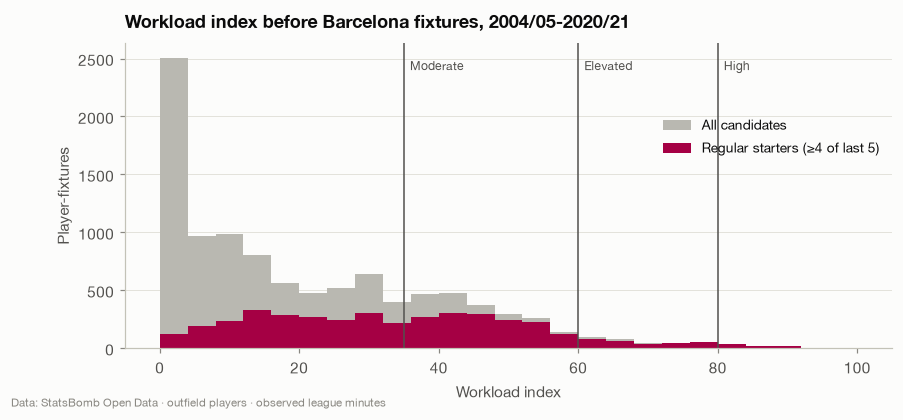

In [3]:
regular = outfield.filter(pl.col("starts_last5") >= 4)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(outfield["workload_index"], bins=np.arange(0, 101, 4), color=style.NEUTRAL, label="All candidates")
ax.hist(regular["workload_index"], bins=np.arange(0, 101, 4), color=style.BARCA, label="Regular starters (≥4 of last 5)")
for x, name in [(35, "Moderate"), (60, "Elevated"), (80, "High")]:
    ax.axvline(x, color=style.INK_2, lw=1)
    ax.annotate(name, (x, ax.get_ylim()[1] * 0.95), xytext=(4, 0), textcoords="offset points", fontsize=8,
                color=style.INK_2, va="top")
ax.set_xlabel("Workload index")
ax.set_ylabel("Player-fixtures")
ax.set_title("Workload index before Barcelona fixtures, 2004/05-2020/21")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.8))
style.caption(ax, style.STATSBOMB_CREDIT + " · outfield players · observed league minutes")
style.savefig(fig, "11_workload_distribution")
plt.show()

Most candidates sit in the Low band: squad players, and regulars in a
normal one-match week. A regular starter in a weekend-to-weekend rhythm
lands around 45-55, and the Elevated and High bands are reached in
genuinely congested stretches (two league matches in four days, long
starting streaks).

## 2. A season through one player's eyes

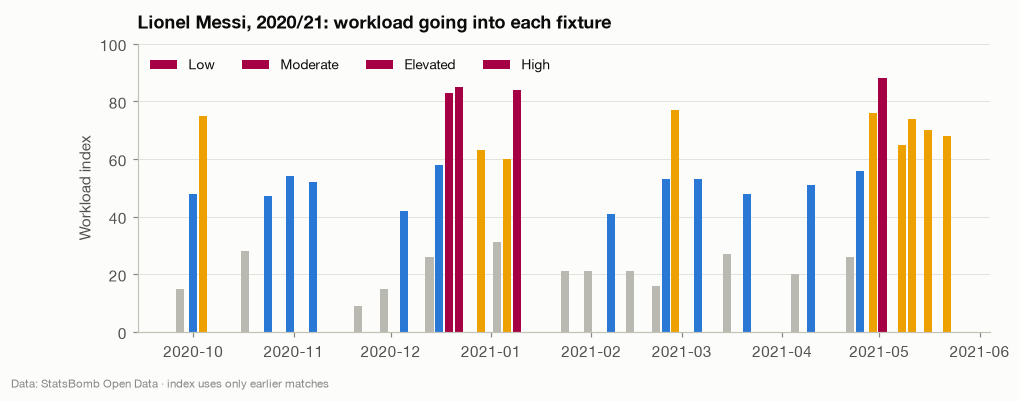

In [4]:
m = pf.filter(pl.col("display_name") == "Lionel Messi", pl.col("season") == "2020/2021").sort("date")
fig, ax = plt.subplots(figsize=(10, 3.4))
colours = {"Low": style.NEUTRAL, "Moderate": style.OPPONENT, "Elevated": style.THIRD, "High": style.BARCA}
ax.bar(m["date"], m["workload_index"], width=2.5, color=[colours[b] for b in m["workload_band"]])
for name, c in colours.items():
    ax.bar([], [], color=c, label=name)
ax.set_ylim(0, 100)
ax.set_ylabel("Workload index")
ax.set_title("Lionel Messi, 2020/21: workload going into each fixture")
ax.legend(ncols=4, loc="upper left")
style.caption(ax, style.STATSBOMB_CREDIT + " · index uses only earlier matches")
style.savefig(fig, "11_messi_workload")
plt.show()

## 3. The squad calendar

Every player-fixture of 2020/21 at once: who carried the load?

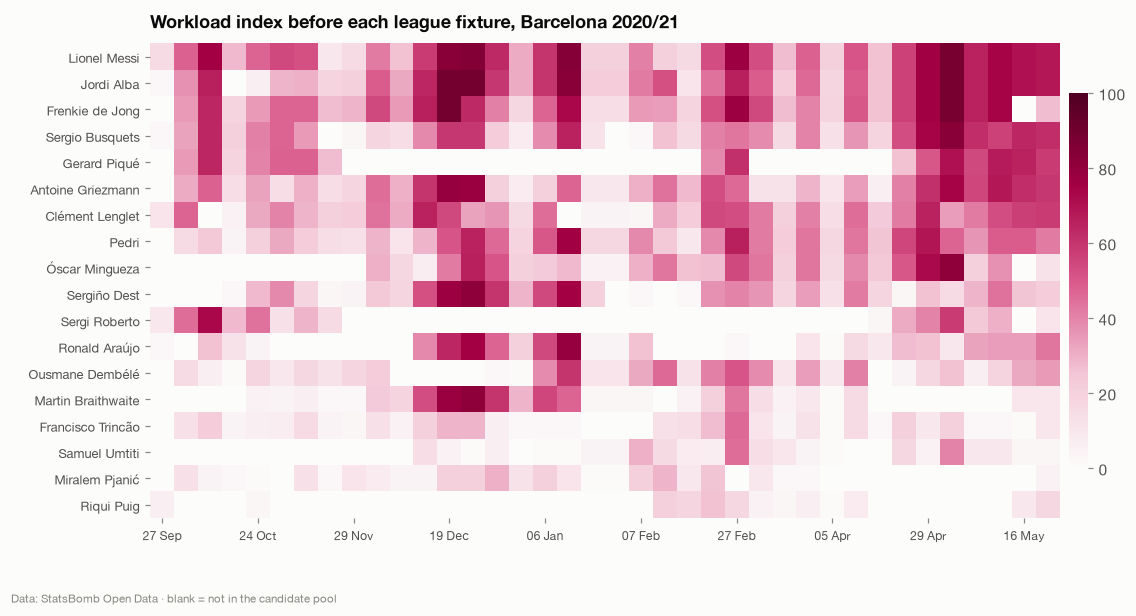

In [5]:
season = outfield.filter(pl.col("season") == "2020/2021", pl.col("competition") == "La Liga")
top = season.group_by("display_name").agg(pl.col("workload_index").mean().alias("m"), pl.len().alias("n")).filter(
    pl.col("n") >= 15).sort("m", descending=True).head(18)["display_name"].to_list()
dates = sorted(season["date"].unique().to_list())
mat = np.full((len(top), len(dates)), np.nan)
for i, name in enumerate(top):
    for r in season.filter(pl.col("display_name") == name).iter_rows(named=True):
        mat[i, dates.index(r["date"])] = r["workload_index"]
fig, ax = plt.subplots(figsize=(11, 5.6))
im = ax.imshow(mat, cmap=style.HEAT, vmin=0, vmax=100, aspect="auto")
ax.set_yticks(range(len(top)), top, fontsize=8.5)
ax.set_xticks(range(0, len(dates), 4), [d.strftime("%d %b") for d in dates[::4]], fontsize=8, rotation=0)
ax.grid(False)
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.set_title("Workload index before each league fixture, Barcelona 2020/21")
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
cb.outline.set_visible(False)
style.caption(ax, style.STATSBOMB_CREDIT + " · blank = not in the candidate pool")
style.savefig(fig, "11_squad_calendar")
plt.show()

The calendar shows the spine of the 2020/21 side (Messi, Busquets, de
Jong, Lenglet, Alba, Pedri) carrying persistently high loads, the midwinter
congestion, and the rotation in the back line.

## 4. Research question: does high workload predict rotation?

For regular starters (started ≥ 4 of the last 5), does a higher workload
index make them less likely to start the next match? Workload and
regularity are entangled (the best players start most and so carry the
most load), so the comparison has to control for it: a logistic
regression of `started` on the workload index together with recent starts,
form and the opponent's strength.

In [6]:
lab = regular.filter(pl.col("started").is_not_null(), pl.col("competition") == "La Liga").with_columns(
    pl.col("started").cast(pl.Int8), (pl.col("workload_index") / 10).alias("workload_10"),
    pl.col("form_rating").fill_null(pl.col("form_rating").median()),
    pl.col("opp_elo").fill_null(pl.col("opp_elo").median()),
)
lab.group_by("workload_band").agg(pl.len().alias("n"), pl.col("started").mean().alias("start_rate")).sort("start_rate",
                                                                                                           descending=True)

workload_band,n,start_rate
str,u32,f64
"""High""",72,0.88
"""Elevated""",235,0.83
"""Moderate""",1379,0.80
"""Low""",1679,0.80


In [7]:
df = lab.select("started", "workload_10", "starts_last5", "starts_last10", "form_rating", "opp_elo",
                "days_since_last_app").drop_nulls().to_pandas()
fit = smf.logit("started ~ workload_10 + starts_last10 + form_rating + opp_elo", data=df).fit(disp=False)
print(fit.summary2().tables[1].round(3))
or_ = np.exp(fit.params["workload_10"])
lo, hi = np.exp(fit.conf_int().loc["workload_10"])
print(f"odds ratio per +10 workload points: {or_:.2f} (95% CI {lo:.2f}-{hi:.2f}), n = {len(df):,}")

               Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
Intercept     -7.081     1.095 -6.467  0.000  -9.227  -4.935
workload_10    0.008     0.024  0.336  0.737  -0.039   0.056
starts_last10  0.213     0.030  7.084  0.000   0.154   0.272
form_rating    0.351     0.076  4.633  0.000   0.203   0.500
opp_elo        0.003     0.001  4.394  0.000   0.002   0.004
odds ratio per +10 workload points: 1.01 (95% CI 0.96-1.06), n = 3,365


Raw start rates *rise* with workload (80% → 88%), but that is the
regularity effect: the players with the highest load are the undisputed
starters. Once recent starts, form and opponent strength are held fixed,
the workload index has **no measurable effect on selection**: the odds
ratio per +10 points is 1.01 with a 95% interval of 0.96-1.06.

The most likely reason is data coverage rather than coaching: rotation is
driven by the midweek cup and European matches, which are missing here, so
the recorded league load is a weak proxy for what coaches were managing.
The index is still offered to the starting-XI model (notebook 16), which
can confirm or reject it with a fair comparison, but nothing is hard-coded
around it.

## 5. Research question: does high workload predict worse performance?

Comparing different players would confound workload with quality (the best
players are both overloaded *and* highly rated), so this compares each
player **with himself**: match rating against workload after removing each
player-season's average (a within-player, fixed-effects comparison).

In [8]:
perf = pf.join(
    store.features("player_match").select("match_id", "player_id", "match_rating", "minutes"),
    on=["match_id", "player_id"], how="inner",
).filter(pl.col("match_rating").is_not_null(), pl.col("minutes") >= 60, pl.col("position_family") != "GK")
perf = perf.with_columns(
    (pl.col("match_rating") - pl.col("match_rating").mean().over("player_id", "season")).alias("rating_dm"),
    (pl.col("workload_index") - pl.col("workload_index").mean().over("player_id", "season")).alias("workload_dm"),
    (pl.col("opp_elo") - pl.col("opp_elo").mean()).alias("opp_elo_c"),
).drop_nulls(["rating_dm", "workload_dm", "opp_elo_c"])
fe = smf.ols("rating_dm ~ workload_dm + opp_elo_c", data=perf.select("rating_dm", "workload_dm", "opp_elo_c").to_pandas()).fit(
    cov_type="cluster", cov_kwds={"groups": perf["player_id"].to_numpy()})
print(fe.summary2().tables[1].round(4))
print(f"n = {perf.height:,} player-matches")
coef = fe.params["workload_dm"] * 20
print(f"effect of +20 workload points on match rating: {coef:+.3f} "
      f"(95% CI {fe.conf_int().loc['workload_dm'][0] * 20:+.3f} to {fe.conf_int().loc['workload_dm'][1] * 20:+.3f})")

              Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
Intercept    0.0025    0.0026   0.9745  0.3298 -0.0025  0.0075
workload_dm  0.0005    0.0006   0.7752  0.4382 -0.0007  0.0016
opp_elo_c   -0.0018    0.0001 -16.0599  0.0000 -0.0020 -0.0016
n = 4,784 player-matches
effect of +20 workload points on match rating: +0.009 (95% CI -0.014 to +0.032)


In [9]:
bins = perf.with_columns(pl.col("workload_dm").cut([-20, -10, 0, 10, 20]).alias("bin")).group_by("bin").agg(
    pl.len().alias("n"), pl.col("workload_dm").mean().alias("workload_vs_own_avg"),
    pl.col("rating_dm").mean().alias("rating_vs_own_avg"),
).sort("workload_vs_own_avg")
bins

bin,n,workload_vs_own_avg,rating_vs_own_avg
enum,u32,f64,f64
"""(-inf, -20]""",518,-26.07,-0.00
"""(-20, -10]""",892,-14.82,0.01
"""(-10, 0]""",1124,-5.06,-0.03
"""(0, 10]""",907,5.04,0.01
"""(10, 20]""",773,14.97,0.00
"""(20, inf]""",570,29.51,0.05


Within players, +20 workload points changes the match rating by +0.009 (95%
interval −0.014 to +0.032), which is indistinguishable from zero and tiny
next to the spread of match ratings (about one rating point). The binned
table shows the same flat line. At the loads recorded in league football,
**workload does not measurably change on-ball performance** in this data.
The opponent's strength, by contrast, matters clearly.

That is an honest null-ish result, and it matches what a careful analyst
would expect: coaches rotate *before* performance drops, so the matches
where overload would show are the ones that were never played. It also
argues against presenting the workload index as a performance predictor.
It is presented as what it is: a load summary that supports rotation
decisions.

## Findings

1. The **Workload Index** is transparent, uses fixed reference points and is
   computed strictly from earlier matches.
2. Observed league workload concentrates on a spine of 6-8 players each
   season.
3. Controlling for regularity and form, **observed workload does not predict
   rotation** (OR 1.01 per +10 points, 95% CI 0.96-1.06), most likely
   because the matches that drive rotation (cups, Europe) are missing.
4. **No measurable performance decline** with workload in this data:
   within-player effects are tiny. The index must not be read as fatigue.
5. The biggest limitation is coverage: cup and European minutes are
   missing.

Next: match-prediction baselines (`12_baselines`).